# M13.13 — Residuo esperado en eventos reales (enmienda 5)

¿Son los residuos reales de 4a-G3T y 4b-G3T (predicción − mediana LVK, sistema del detector, los 9 eventos de M13.7)
compatibles con los residuos que el mismo modelo comete en val de G3T en la región del evento (Mc y SNR de red)?

Método fijado en `docs/experiments/M13_13_G3T_taper.md`, *Enmienda 5*, antes de ejecutar:

- Residuos reales: los del JSON de `M13_13_real_events.ipynb` (no se repite la inferencia). Posteriores LVK: mismas
  funciones de lectura que M13.7/M13.13; se comprueba que las medianas coinciden con el JSON.
- r_sim = pred − verdad en val de G3T; vecindario por |Mc_true/Mc_LVK − 1| y |ρ/ρ_LVK − 1| con ampliación fija.
- r_ref = r_sim + (s − mediana LVK); u = fracción de r_ref ≤ residuo real.

> **Roles.** Evaluación solamente; ni los eventos reales ni este análisis intervienen en elección o ajuste alguno.
> Con n = 9 la potencia solo alcanza para desajustes groseros; LVK es una referencia, no la verdad.

Solo CPU (lee ~6 MB de etiquetas y SNR del HDF5 de G3, y las posteriores LVK). Entregado sin ejecutar.

## 1. Parámetros (fijados en la enmienda 5)

In [1]:
PRIMARY = "M13_13_4a_G3T_s123"
SECONDARY = "M13_13_4b_G3T_s123"
MODELS = [PRIMARY, SECONDARY]          # fixed order: also the RNG traversal order
REAL_EVENTS_STAMP = "20261110T130749Z"  # executed run of M13_13_real_events.ipynb

# Neighbourhood windows (|Mc_true/Mc_LVK - 1|, |rho/rho_LVK - 1|), tried in this order.
WINDOWS = [(0.10, 0.25), (0.20, 0.25), (0.20, 0.40)]
MIN_NEIGHBOURS = 200
PRIOR_PERCENTILES = (2, 98)             # of train Mc_true (G3T y_train.npy) -> flag "borde_prior"

SEED = 151301
N_DRAWS = 20_000
U_RANGE = (0.05, 0.95)                  # "compatible" if U_RANGE[0] <= u <= U_RANGE[1]
P_OUTSIDE = U_RANGE[0] + (1 - U_RANGE[1])  # = 0.10 under H1
N_OUTSIDE_H2 = 4                        # >= 4 outside -> mismatch (H2)
N_LOW_SIGN = 7                          # >= 7 with u < 0.5 -> sign bias (descriptive)

## 2. Imports y rutas

In [2]:
from pathlib import Path
from datetime import datetime, timezone
from math import comb
import sys, ast, json, hashlib, re
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

root = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
             if (p / "src/paths.py").is_file()), None)
if root is None:
    raise RuntimeError("Abrir desde cbc_pe")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
from src.paths import resolve_project_root, resolve_data_root, resolve_processed_artifact, dataset_processed_dir

PROJECT_ROOT = resolve_project_root()
def read_json(path):
    return json.loads(Path(path).read_text())
def require(condition, message):
    if not condition:
        raise ValueError(message)
def file_sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()
def array_sha256(a):
    return hashlib.sha256(np.ascontiguousarray(a).tobytes()).hexdigest()

LABELS = ["chirp_mass", "total_mass", "chi_eff"]
DETECTORS = ["H1", "L1", "V1"]

# G3 HDF5 exactly as in M13_13_real_events.ipynb (G3 train-config contract).
TRAIN_CFG_PATH = PROJECT_ROOT / "configs/experiments/m13/train_m13_4b_G3aug_s123.json"
train_cfg = read_json(TRAIN_CFG_PATH)
DATA_ROOT = resolve_data_root(config_data_root=train_cfg["data_root"])
G3_H5 = resolve_processed_artifact(data_root=DATA_ROOT, dataset_id=train_cfg["dataset"]["dataset_id"],
                                   file_name=train_cfg["dataset"]["dataset_file"])

REAL_EVENTS_NOTEBOOK = PROJECT_ROOT / "notebooks/m13/M13_13_real_events.ipynb"
REAL_EVENTS_JSON = DATA_ROOT / f"results/M13_3/M13_13/real_events/M13_13_real_events_{REAL_EVENTS_STAMP}.json"
M13_7_NOTEBOOK = PROJECT_ROOT / "notebooks/m13/M13_7_pipeline_provisional_4b.ipynb"
M10_DATASET_ID = read_json(PROJECT_ROOT / "configs/experiments/train_500k_M10_inputzscore_resdilated_emb64_d124_bs256_seed123.json")["dataset"]["dataset_id"]
EVENT_LIST_PATH = DATA_ROOT / "results" / M10_DATASET_ID / "real_events_m10_500k_lvk_comparison/multi_event_all_catalog_candidates.csv"

# Same posterior choice as M13.7 / M13_13_real_events (read by the reused M13.7 functions).
PE_DIR = DATA_ROOT / "external/gwtc3_pe"
PE_VARIANT = "mixed_cosmo"
PE_GROUP = "C01:Mixed"

RUN_INFO = {tag: DATA_ROOT / "results/M13_3" / tag / "run_info.json" for tag in MODELS}
VAL_NPZ = {tag: DATA_ROOT / "results/M13_3" / tag / "val_predictions_embeddings.npz" for tag in MODELS}
G3T_DATASET_ID = read_json(RUN_INFO[PRIMARY])["config"]["dataset"]["dataset_id"]
Y_TRAIN_G3T = dataset_processed_dir(DATA_ROOT, G3T_DATASET_ID) / "fp16_memmap/y_train.npy"

RUN_STAMP = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
OUTPUT_DIR = DATA_ROOT / "results/M13_3/M13_13/expected_residual"

inputs_to_check = [("real-events notebook", REAL_EVENTS_NOTEBOOK), ("real-events JSON", REAL_EVENTS_JSON),
    ("M13.7 notebook", M13_7_NOTEBOOK), ("cohort", EVENT_LIST_PATH), ("G3 HDF5", G3_H5),
    ("G3T y_train", Y_TRAIN_G3T)]
inputs_to_check += [(f"run_info {t}", p) for t, p in RUN_INFO.items()]
inputs_to_check += [(f"val npz {t}", p) for t, p in VAL_NPZ.items()]
path_audit = pd.DataFrame([dict(role=r, path=str(p), exists=p.is_file()) for r, p in inputs_to_check])
with pd.option_context("display.max_colwidth", None):
    display(path_audit)
require(path_audit.exists.all(), "Missing required inputs; inspect path table")

,role,path,exists
0,real-events notebook,/afs/ciemat.es/user/v/vserrano/Desktop/gw/Gravitational-Waves-Lab/cbc_pe/notebooks/m13/M13_13_real_events.ipynb,True
1,real-events JSON,/data/vserrano/cbc_pe_data/results/M13_3/M13_13/real_events/M13_13_real_events_20261110T130749Z.json,True
2,M13.7 notebook,/afs/ciemat.es/user/v/vserrano/Desktop/gw/Gravitational-Waves-Lab/cbc_pe/notebooks/m13/M13_7_pipeline_provisional_4b.ipynb,True
3,cohort,/data/vserrano/cbc_pe_data/results/bbh_processed_4s_seobnrv4opt_snr10-25_n500_000/real_events_m10_500k_lvk_comparison/multi_event_all_catalog_candidates.csv,True
4,G3 HDF5,/data/vserrano/cbc_pe_data/processed/M13_G3_band1024_w16_500k/m13_G3_band1024_w16_500k_trainio.h5,True
5,G3T y_train,/data/vserrano/cbc_pe_data/processed/M13_G3_band1024_w16_500k/m13_13_g3t/fp16_memmap/y_train.npy,True
6,run_info M13_13_4a_G3T_s123,/data/vserrano/cbc_pe_data/results/M13_3/M13_13_4a_G3T_s123/run_info.json,True
7,run_info M13_13_4b_G3T_s123,/data/vserrano/cbc_pe_data/results/M13_3/M13_13_4b_G3T_s123/run_info.json,True
8,val npz M13_13_4a_G3T_s123,/data/vserrano/cbc_pe_data/results/M13_3/M13_13_4a_G3T_s123/val_predictions_embeddings.npz,True
9,val npz M13_13_4b_G3T_s123,/data/vserrano/cbc_pe_data/results/M13_3/M13_13_4b_G3T_s123/val_predictions_embeddings.npz,True


## 3. Residuos reales y posteriores LVK

Residuos del JSON de `M13_13_real_events` para los dos modelos G3T. `pe_file` y `read_pe_samples` se ejecutan desde la
celda 27 de M13.7 (como hace `M13_13_real_events`), sin copiarlas; su sha256 va al JSON. Se exige que la mediana LVK
recalculada coincida con la del JSON y que la cohorte sea la misma.

In [3]:
real_json = read_json(REAL_EVENTS_JSON)
require(real_json["provenance"]["cohort_sha256"] == file_sha256(EVENT_LIST_PATH), "Cohort differs from M13_13_real_events")
EVENTS = list(real_json["events"])
require(len(EVENTS) == 9, "Expected the 9 events of M13.7")
real = pd.DataFrame(real_json["per_event"])
real = real[real.model.isin(MODELS)].reset_index(drop=True)
require(len(real) == len(MODELS) * len(EVENTS) * len(LABELS)
        and not real.duplicated(["model", "event", "label"]).any(), "Residual table incomplete or duplicated")
require(np.allclose(real.residual, real.prediction - real.lvk_pe_median, rtol=0, atol=1e-12), "Residual definition")

m13_7_cells = read_json(M13_7_NOTEBOOK)["cells"]
pe_cell_source = "".join(m13_7_cells[27]["source"])
tree = ast.parse(pe_cell_source)
tree.body = [n for n in tree.body if isinstance(n, ast.FunctionDef) and n.name in ("pe_file", "read_pe_samples")]
require(len(tree.body) == 2, "M13.7 cell 27 does not define pe_file and read_pe_samples")
exec(compile(tree, "M13_7_cell_27", "exec"), globals())
reused_cell = dict(cell=27, names=["pe_file", "read_pe_samples"],
                   sha256=hashlib.sha256(pe_cell_source.encode()).hexdigest())
require(reused_cell["sha256"] == real_json["provenance"]["reused_m13_7_cells"]["cell_27"]["sha256"],
        "M13.7 cell 27 changed since M13_13_real_events")

pe_samples, pe_info = {}, {}
for event in EVENTS:
    path = pe_file(event)
    require(path is not None, f"{event}: no PE file")
    samples, info = read_pe_samples(path)
    require(info["size"] == real_json["lvk_posterior"]["files"][event]["size"], f"{event}: PE file size differs")
    info["sha256"] = file_sha256(path)
    pe_samples[event], pe_info[event] = samples, info

medians = {(e, l): float(np.median(pe_samples[e][:, j])) for e in EVENTS for j, l in enumerate(LABELS)}
require(np.allclose(real.apply(lambda r: medians[(r.event, r.label)], axis=1), real.lvk_pe_median,
                    rtol=1e-12, atol=0.0), "LVK medians differ from M13_13_real_events")

cohort = pd.read_csv(EVENT_LIST_PATH)
require(not cohort.event.duplicated().any(), "Duplicate event in cohort")
events = cohort.loc[cohort.event.isin(EVENTS), ["event", "network_snr_lvk"]].copy()
require(len(events) == 9 and events.network_snr_lvk.notna().all(), "Catalog SNR missing")
events["mc_lvk"] = events.event.map(lambda e: medians[(e, "chirp_mass")])
events = events.sort_values("mc_lvk", ignore_index=True)  # fixed event order (RNG and figures)
display(events)

,event,network_snr_lvk,mc_lvk
0,GW200202_154313,10.8,8.148216
1,GW200316_215756,10.3,10.676260
2,GW191215_223052,11.2,24.867089
3,GW200129_065458,26.8,32.063561
4,GW200311_115853,17.8,32.669543
5,GW200208_130117,10.8,38.816372
6,GW200224_222234,20.0,40.926222
7,GW200219_094415,10.7,43.736712
8,GW191230_180458,10.4,62.064472


## 4. Simulación: val de G3T

`pred_val` e `y_val` están estandarizados; se desestandarizan con el `y_mean`/`y_std` guardado en cada npz.
`idx_val` es el índice de fila del HDF5 (el mismo en G3 y G3T); la verdad desestandarizada se compara con `y` del HDF5
de G3 en esas filas. SNR simulado: √(Σ snr_det²) de G3 — aproximado para G3T (el clic aporta poco SNR en la banda) y
óptimo, no matched filter como `network_snr_lvk`.

In [4]:
sim = {}
for tag in MODELS:
    with np.load(VAL_NPZ[tag], allow_pickle=False) as z:
        require(list(z["label_names"]) == LABELS, f"{tag}: label order")
        y_mean, y_std = z["y_mean"].astype(float), z["y_std"].astype(float)
        pred = z["pred_val"].astype(float) * y_std + y_mean
        truth = z["y_val"].astype(float) * y_std + y_mean
        sim[tag] = dict(idx=z["idx_val"].copy(), pred=pred, truth=truth, residual=pred - truth)
require(np.array_equal(sim[PRIMARY]["idx"], sim[SECONDARY]["idx"]), "Val rows differ between models")
require(np.allclose(sim[PRIMARY]["truth"], sim[SECONDARY]["truth"], rtol=0, atol=1e-6 * np.abs(sim[PRIMARY]["truth"]).max()),
        "Val truth differs between models")
idx_val = sim[PRIMARY]["idx"]
require(len(np.unique(idx_val)) == len(idx_val), "Duplicate val rows")

with h5py.File(G3_H5, "r") as h:
    y_h5 = h["y"][:]
    snr_h5 = np.column_stack([h[f"snr_{d}"][:] for d in DETECTORS])
    split_h5 = h["split"][:]
split_val = np.array([s.decode() if isinstance(s, bytes) else str(s) for s in split_h5[idx_val]])
require((split_val == "val").all(), "idx_val rows are not split=val in the G3 HDF5")
# float32 standardisation round trip: tolerance relative to the label scale.
require(np.all(np.abs(y_h5[idx_val] - sim[PRIMARY]["truth"]) <= 1e-4 * y_std), "Val truth != G3 HDF5 y[idx_val]")
require(np.isfinite(snr_h5[idx_val]).all(), "Nonfinite snr_* in val rows")
rho_val = np.sqrt((snr_h5[idx_val] ** 2).sum(axis=1))
mc_val = sim[PRIMARY]["truth"][:, 0]

y_train = np.load(Y_TRAIN_G3T)
require(y_train.shape == (400_000, 3), "Unexpected G3T y_train shape")
with np.load(resolve_processed_artifact(data_root=DATA_ROOT, dataset_id=G3T_DATASET_ID,
             file_name=read_json(RUN_INFO[PRIMARY])["config"]["dataset"]["label_stats_file"])) as stats:
    # y_train.npy is physical: its mean must match the train-only scaler.
    require(np.all(np.abs(y_train.astype(float).mean(axis=0) - stats["y_mean"]) <= 1e-3 * stats["y_std"]),
            "y_train.npy is not the physical train split")
mc_prior_lo, mc_prior_hi = np.percentile(y_train[:, 0].astype(float), PRIOR_PERCENTILES)
print(f"Train Mc P{PRIOR_PERCENTILES[0]}-P{PRIOR_PERCENTILES[1]}: [{mc_prior_lo:.3f}, {mc_prior_hi:.3f}]")
print(f"Val rho (G3, optimal): median {np.median(rho_val):.2f}, range [{rho_val.min():.2f}, {rho_val.max():.2f}]")

Train Mc P2-P98: [10.410, 70.814]
Val rho (G3, optimal): median 17.46, range [10.00, 25.00]


## 5. Vecindario de cada evento

Depende solo de la verdad y del SNR de val, por lo que es el mismo para los dos modelos. Ventanas en el orden fijo de
`WINDOWS`; `sin_soporte` si ninguna alcanza `MIN_NEIGHBOURS` (se excluye de los criterios).

In [5]:
neighbours, window_rows = {}, []
for r in events.itertuples(index=False):
    mc_dev = np.abs(mc_val / r.mc_lvk - 1)
    rho_dev = np.abs(rho_val / r.network_snr_lvk - 1)
    chosen = None
    for k, (w_mc, w_rho) in enumerate(WINDOWS):
        mask = (mc_dev <= w_mc) & (rho_dev <= w_rho)
        if mask.sum() >= MIN_NEIGHBOURS:
            chosen = k
            break
    supported = chosen is not None
    neighbours[r.event] = np.flatnonzero(mask) if supported else None
    window_rows.append(dict(event=r.event, mc_lvk=r.mc_lvk, network_snr_lvk=r.network_snr_lvk,
        window=chosen, window_mc=WINDOWS[chosen][0] if supported else np.nan,
        window_rho=WINDOWS[chosen][1] if supported else np.nan,
        n_neighbours=int(mask.sum()),  # with the last window tried when unsupported
        sin_soporte=not supported, borde_prior=not (mc_prior_lo <= r.mc_lvk <= mc_prior_hi)))
windows_table = pd.DataFrame(window_rows)
display(windows_table)

,event,mc_lvk,network_snr_lvk,window,window_mc,window_rho,n_neighbours,sin_soporte,borde_prior
0,GW200202_154313,8.148216,10.8,NaN,NaN,NaN,182,True,True
1,GW200316_215756,10.676260,10.3,1.0,0.2,0.25,282,False,False
2,GW191215_223052,24.867089,11.2,0.0,0.1,0.25,1146,False,False
3,GW200129_065458,32.063561,26.8,0.0,0.1,0.25,1659,False,False
4,GW200311_115853,32.669543,17.8,0.0,0.1,0.25,3125,False,False
5,GW200208_130117,38.816372,10.8,0.0,0.1,0.25,1388,False,False
6,GW200224_222234,40.926222,20.0,0.0,0.1,0.25,4056,False,False
7,GW200219_094415,43.736712,10.7,0.0,0.1,0.25,1396,False,False
8,GW191230_180458,62.064472,10.4,0.0,0.1,0.25,1028,False,False


## 6. Distribución de referencia y u

Por (modelo, evento, etiqueta): 20 000 pares (fila del vecindario, muestra de la posterior LVK), ambos con reemplazo;
r_ref = r_sim + (s − mediana LVK). Un solo `default_rng(151301)` recorrido en orden modelo → evento (Mc_LVK creciente) →
etiqueta. Los eventos `sin_soporte` no consumen extracciones. `u_noconv` usa r_sim del vecindario sin convolución.

In [6]:
rng = np.random.default_rng(SEED)
real_idx = real.set_index(["model", "event", "label"])
rows = []
for tag in MODELS:
    for w in windows_table.itertuples(index=False):
        for j, label in enumerate(LABELS):
            observed = float(real_idx.loc[(tag, w.event, label), "residual"])
            row = dict(model=tag, event=w.event, label=label, mc_lvk=w.mc_lvk, network_snr_lvk=w.network_snr_lvk,
                       n_neighbours=w.n_neighbours, window_mc=w.window_mc, window_rho=w.window_rho,
                       sin_soporte=w.sin_soporte, borde_prior=w.borde_prior, residual_real=observed)
            if not w.sin_soporte:
                r_sim = sim[tag]["residual"][neighbours[w.event], j]
                s = pe_samples[w.event][:, j]
                r_ref = (r_sim[rng.integers(0, len(r_sim), N_DRAWS)]
                         + s[rng.integers(0, len(s), N_DRAWS)] - medians[(w.event, label)])
                p5, p50, p95 = np.percentile(r_ref, [5, 50, 95])
                row.update(r_ref_median=p50, r_ref_p5=p5, r_ref_p95=p95,
                           r_sim_median=float(np.median(r_sim)),
                           u=float(np.mean(r_ref <= observed)), u_noconv=float(np.mean(r_sim <= observed)))
            rows.append(row)
per_event = pd.DataFrame(rows)
per_event["compatible"] = per_event.u.between(*U_RANGE).where(~per_event.sin_soporte)  # NaN if sin_soporte
for tag in MODELS:
    print(tag)
    display(per_event[per_event.model == tag].drop(columns="model"))

M13_13_4a_G3T_s123


,event,label,mc_lvk,network_snr_lvk,n_neighbours,window_mc,window_rho,sin_soporte,borde_prior,residual_real,r_ref_median,r_ref_p5,r_ref_p95,r_sim_median,u,u_noconv,compatible
0,GW200202_154313,chirp_mass,8.148216,10.8,182,NaN,NaN,True,True,2.607152,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,GW200202_154313,total_mass,8.148216,10.8,182,NaN,NaN,True,True,11.049735,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,GW200202_154313,chi_eff,8.148216,10.8,182,NaN,NaN,True,True,0.574987,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,GW200316_215756,chirp_mass,10.676260,10.3,282,0.2,0.25,False,False,-0.463513,0.386327,-1.323530,2.850651,0.416336,0.22985,0.226950,True
4,GW200316_215756,total_mass,10.676260,10.3,282,0.2,0.25,False,False,1.421356,2.528114,-10.481429,14.342002,1.574190,0.42255,0.478723,True
5,GW200316_215756,chi_eff,10.676260,10.3,282,0.2,0.25,False,False,-0.066245,0.099054,-0.433123,0.669636,0.062822,0.29260,0.319149,True
6,GW191215_223052,chirp_mass,24.867089,11.2,1146,0.1,0.25,False,False,-3.615638,0.936291,-3.695588,15.218047,0.836829,0.05290,0.045375,True
7,GW191215_223052,total_mass,24.867089,11.2,1146,0.1,0.25,False,False,-7.251155,3.078041,-11.261925,21.554909,2.936659,0.10680,0.095986,True
8,GW191215_223052,chi_eff,24.867089,11.2,1146,0.1,0.25,False,False,-0.277456,0.034876,-0.316813,0.420831,0.042946,0.07105,0.043630,True
9,GW200129_065458,chirp_mass,32.063561,26.8,1659,0.1,0.25,False,False,-1.449182,0.567572,-4.605418,9.249792,0.555455,0.25360,0.226040,True


M13_13_4b_G3T_s123


,event,label,mc_lvk,network_snr_lvk,n_neighbours,window_mc,window_rho,sin_soporte,borde_prior,residual_real,r_ref_median,r_ref_p5,r_ref_p95,r_sim_median,u,u_noconv,compatible
27,GW200202_154313,chirp_mass,8.148216,10.8,182,NaN,NaN,True,True,0.245533,NaN,NaN,NaN,NaN,NaN,NaN,NaN
28,GW200202_154313,total_mass,8.148216,10.8,182,NaN,NaN,True,True,2.522374,NaN,NaN,NaN,NaN,NaN,NaN,NaN
29,GW200202_154313,chi_eff,8.148216,10.8,182,NaN,NaN,True,True,0.158500,NaN,NaN,NaN,NaN,NaN,NaN,NaN
30,GW200316_215756,chirp_mass,10.676260,10.3,282,0.2,0.25,False,False,0.556396,0.188605,-1.073761,2.415640,0.166829,0.65340,0.648936,True
31,GW200316_215756,total_mass,10.676260,10.3,282,0.2,0.25,False,False,5.228964,2.756666,-9.494843,13.210142,2.122020,0.68455,0.762411,True
32,GW200316_215756,chi_eff,10.676260,10.3,282,0.2,0.25,False,False,0.105100,0.075310,-0.413102,0.577582,0.055763,0.53950,0.574468,True
33,GW191215_223052,chirp_mass,24.867089,11.2,1146,0.1,0.25,False,False,-1.844552,0.886486,-3.449020,14.746701,0.791879,0.15305,0.133508,True
34,GW191215_223052,total_mass,24.867089,11.2,1146,0.1,0.25,False,False,-3.969073,2.846241,-10.590004,20.989988,2.599553,0.17950,0.171030,True
35,GW191215_223052,chi_eff,24.867089,11.2,1146,0.1,0.25,False,False,-0.163336,0.035694,-0.309884,0.408328,0.040224,0.16480,0.101222,True
36,GW200129_065458,chirp_mass,32.063561,26.8,1659,0.1,0.25,False,False,-0.869552,0.463629,-4.501051,9.751081,0.440246,0.32310,0.299578,True


## 7. Criterios por etiqueta y modelo

Sobre los eventos con soporte (u convolucionada). H2 si `n_outside` ≥ 4; sesgo de signo (descriptivo) si `n_u_below_half` ≥ 7;
en otro caso "no se detecta desajuste". Umbrales absolutos; las P binomiales de cola superior se dan para el n real.

In [7]:
def binom_tail(k, n, p):
    """P(X >= k), X ~ Binomial(n, p)."""
    return float(sum(comb(n, i) * p ** i * (1 - p) ** (n - i) for i in range(k, n + 1)))

crit_rows = []
for (tag, label), g in per_event[~per_event.sin_soporte].groupby(["model", "label"], sort=False):
    n = len(g)
    n_out = int((~g.u.between(*U_RANGE)).sum())
    n_low = int((g.u < 0.5).sum())
    h2, sign = n_out >= N_OUTSIDE_H2, n_low >= N_LOW_SIGN
    verdict = ("desajuste (H2)" if h2 else "") + ("; " if h2 and sign else "") + ("sesgo de signo (descriptivo)" if sign else "")
    crit_rows.append(dict(model=tag, label=label, n_supported=n,
        n_borde_prior=int(g.borde_prior.sum()), n_outside=n_out,
        p_h1_n_outside_ge_obs=binom_tail(n_out, n, P_OUTSIDE), p_h1_ge_threshold=binom_tail(N_OUTSIDE_H2, n, P_OUTSIDE),
        n_u_below_half=n_low, p_h1_n_low_ge_obs=binom_tail(n_low, n, 0.5),
        p_h1_low_ge_threshold=binom_tail(N_LOW_SIGN, n, 0.5),
        n_outside_noconv=int((~g.u_noconv.between(*U_RANGE)).sum()),
        mismatch_h2=h2, sign_bias=sign, verdict=verdict or "no se detecta desajuste"))
criteria = pd.DataFrame(crit_rows)
require(len(criteria) == len(MODELS) * len(LABELS) or windows_table.sin_soporte.all(), "Missing criteria rows")
display(criteria)

,model,label,n_supported,n_borde_prior,n_outside,p_h1_n_outside_ge_obs,p_h1_ge_threshold,n_u_below_half,p_h1_n_low_ge_obs,p_h1_low_ge_threshold,n_outside_noconv,mismatch_h2,sign_bias,verdict
0,M13_13_4a_G3T_s123,chirp_mass,8,0,0,1.0,0.005024,8,0.003906,0.035156,1,False,True,sesgo de signo (descriptivo)
1,M13_13_4a_G3T_s123,total_mass,8,0,0,1.0,0.005024,8,0.003906,0.035156,0,False,True,sesgo de signo (descriptivo)
2,M13_13_4a_G3T_s123,chi_eff,8,0,0,1.0,0.005024,8,0.003906,0.035156,1,False,True,sesgo de signo (descriptivo)
3,M13_13_4b_G3T_s123,chirp_mass,8,0,0,1.0,0.005024,6,0.144531,0.035156,0,False,False,no se detecta desajuste
4,M13_13_4b_G3T_s123,total_mass,8,0,0,1.0,0.005024,6,0.144531,0.035156,0,False,False,no se detecta desajuste
5,M13_13_4b_G3T_s123,chi_eff,8,0,0,1.0,0.005024,4,0.636719,0.035156,0,False,False,no se detecta desajuste


## 8. Figuras

Una por modelo, un panel por etiqueta. Eventos ordenados por Mc_LVK. Barra gris: banda 5–95 % de r_ref; raya: su mediana;
punto: residuo real (rojo si u fuera de [0,05; 0,95]). `sin_soporte`: sin banda; `borde_prior`: etiqueta con `*`.

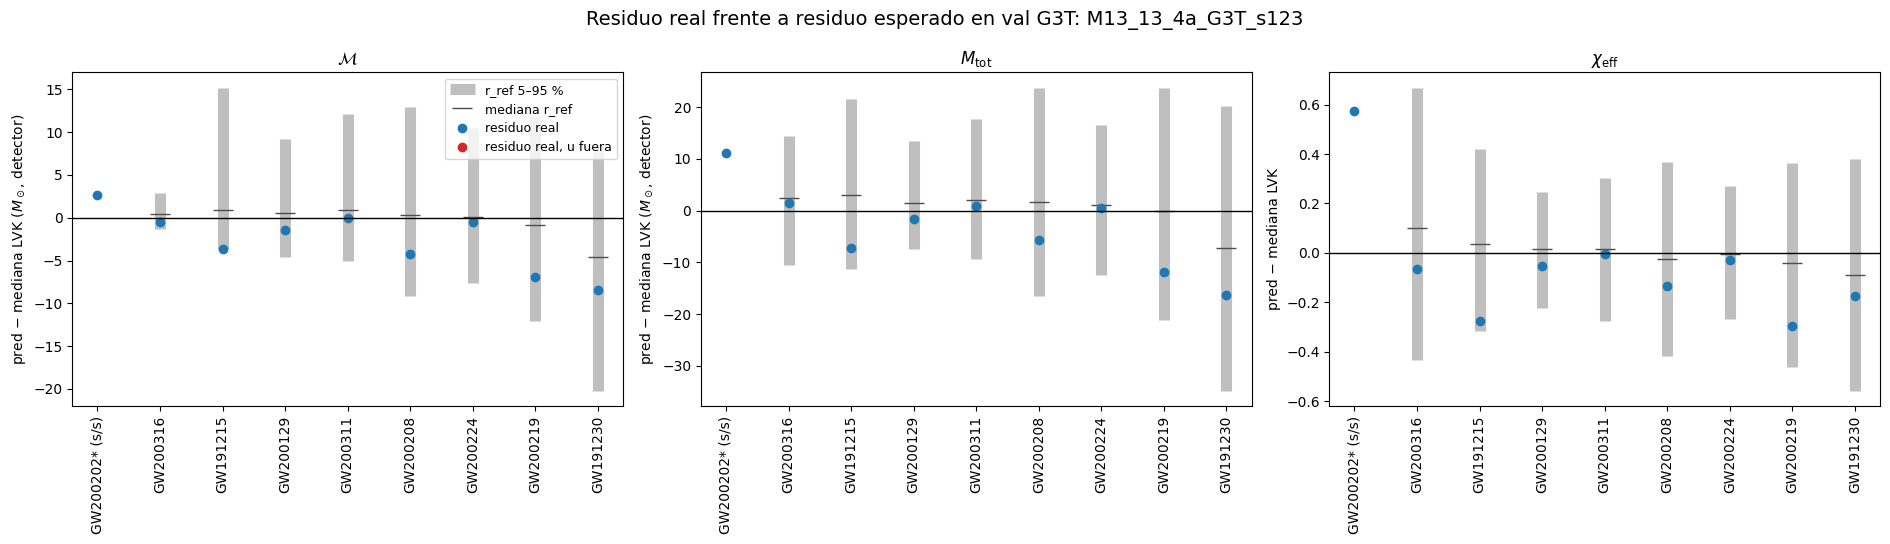

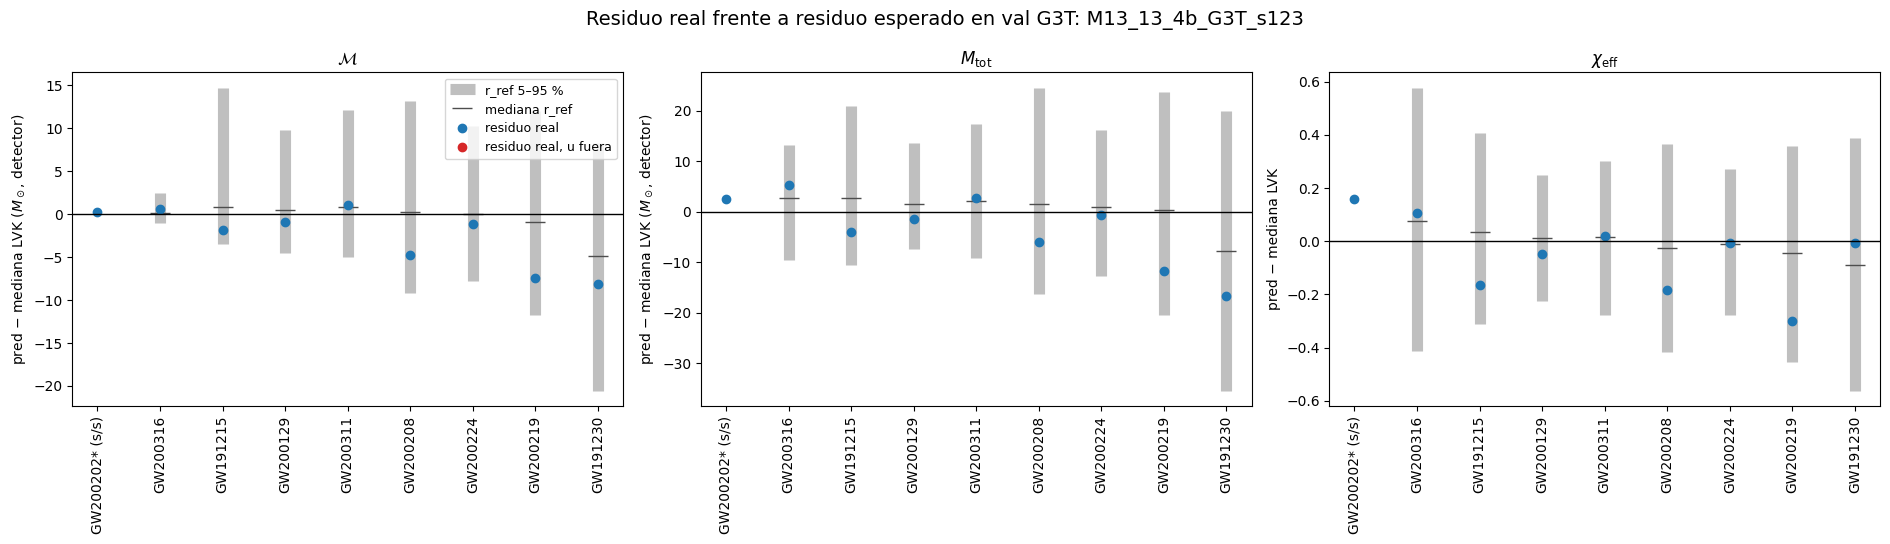

In [8]:
NICE_LABELS = {"chirp_mass": r"$\mathcal{M}$", "total_mass": r"$M_{\mathrm{tot}}$", "chi_eff": r"$\chi_\mathrm{eff}$"}
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
figure_paths = []
for tag in MODELS:
    fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
    fig.suptitle(f"Residuo real frente a residuo esperado en val G3T: {tag}", fontsize=14)
    for ax, label in zip(axes, LABELS):
        g = per_event[(per_event.model == tag) & (per_event.label == label)].reset_index(drop=True)
        x = np.arange(len(g))
        ok = ~g.sin_soporte.to_numpy()
        ax.vlines(x[ok], g.r_ref_p5[ok], g.r_ref_p95[ok], color="0.75", linewidth=8, label="r_ref 5–95 %")
        ax.plot(x[ok], g.r_ref_median[ok], "_", color="0.3", markersize=14, label="mediana r_ref")
        outside = ok & ~g.u.between(*U_RANGE).to_numpy()
        ax.plot(x[~outside], g.residual_real[~outside], "o", color="C0", label="residuo real")
        ax.plot(x[outside], g.residual_real[outside], "o", color="C3", label="residuo real, u fuera")
        ax.axhline(0, color="black", linewidth=1)
        unit = r" ($M_\odot$, detector)" if label != "chi_eff" else ""
        ax.set(title=NICE_LABELS[label], ylabel="pred − mediana LVK" + unit)
        ax.set_xticks(x)
        ax.set_xticklabels([e.split("_")[0] + ("*" if b else "") + (" (s/s)" if s else "")
                            for e, b, s in zip(g.event, g.borde_prior, g.sin_soporte)], rotation=90)
    axes[0].legend(fontsize=9)
    fig.tight_layout()
    path = OUTPUT_DIR / f"M13_13_expected_residual_{RUN_STAMP}_{tag}.png"
    with path.open("xb") as f:
        fig.savefig(f, format="png", dpi=150, bbox_inches="tight")
    figure_paths.append(str(path))
    plt.show()

## 9. Resumen JSON (modo `'x'`)

sha256 de todas las entradas salvo el HDF5 de G3 (~100 GB): de éste se guardan ruta, tamaño y el sha256 de los arrays
leídos (`y`, `snr_*` en las filas de val).

In [9]:
json_path = OUTPUT_DIR / f"M13_13_expected_residual_{RUN_STAMP}.json"
sha = {role: file_sha256(Path(p)) for role, p in inputs_to_check if role != "G3 HDF5"}
summary = dict(
    created_utc=datetime.now(timezone.utc).isoformat(), run_stamp=RUN_STAMP, descriptive=True,
    preregistration="docs/experiments/M13_13_G3T_taper.md, Enmienda 5",
    data_roles="real events: evaluation only; val G3T: simulated residual reference; train: prior percentiles only",
    parameters=dict(models=MODELS, primary=PRIMARY, secondary=SECONDARY, windows=WINDOWS,
        min_neighbours=MIN_NEIGHBOURS, prior_percentiles=PRIOR_PERCENTILES, seed=SEED, n_draws=N_DRAWS,
        rng_order="model -> event (increasing Mc_LVK) -> label; supported events only",
        u_range=U_RANGE, p_outside_h1=P_OUTSIDE, n_outside_h2=N_OUTSIDE_H2, n_low_sign=N_LOW_SIGN),
    definitions=dict(residual_real="prediction - median LVK posterior (detector frame), from M13_13_real_events",
        r_sim="pred - truth on G3T val (destandardised with each npz y_mean/y_std)",
        rho_sim="sqrt(sum snr_H1^2+snr_L1^2+snr_V1^2) of G3 HDF5 (optimal; approximate for G3T)",
        rho_real="network_snr_lvk of the catalog (matched filter)",
        r_ref="r_sim + (s - median LVK), s resampled from the LVK posterior", u="mean(r_ref <= residual_real)",
        u_noconv="mean(r_sim <= residual_real)"),
    inputs=dict(paths={role: str(p) for role, p in inputs_to_check}, sha256=sha,
        g3_hdf5=dict(path=str(G3_H5), size=G3_H5.stat().st_size, sha256="not computed (size)",
                     y_val_rows_sha256=array_sha256(y_h5[idx_val]), snr_val_rows_sha256=array_sha256(snr_h5[idx_val])),
        idx_val_sha256=array_sha256(idx_val), reused_m13_7_cell=reused_cell,
        lvk_posterior=dict(variant=PE_VARIANT, group=PE_GROUP, files=pe_info),
        versions=dict(python=sys.version, numpy=np.__version__, pandas=pd.__version__)),
    train_mc_prior=dict(lo=mc_prior_lo, hi=mc_prior_hi),
    windows=windows_table.to_dict("records"), per_event=per_event.to_dict("records"),
    criteria=criteria.to_dict("records"), figures=figure_paths)
with json_path.open("x", encoding="utf-8") as f:
    # numpy scalars -> Python scalars; NaN kept as NaN; anything else as text.
    json.dump(summary, f, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
print("Summary:", json_path)

Summary: /data/vserrano/cbc_pe_data/results/M13_3/M13_13/expected_residual/M13_13_expected_residual_20261110T142748Z.json


## 10. Lectura

Lectura (enmienda 5; 9 eventos, una semilla por modelo). GW200202 (𝓜 = 8,15, por debajo del P2 de train, 10,4) queda sin_soporte con 182 vecinos y fuera de los criterios. En los otros 8 eventos, las 48 combinaciones de modelo y etiqueta tienen u ∈ [0,05; 0,95], así que no se detecta desajuste en ninguna etiqueta ni en ningún modelo. El sesgo negativo de GW191230 ya aparece en simulación: la mediana del residuo en su vecindario es de −4,3 / −6,5 (𝓜 / M_tot) con 4a y de −4,6 / −7,1 con 4b, y el residuo real cae en u ≈ 0,3. Es coherente con la regresión a la media del estimador. 4a-G3T tiene u < 0,5 en 8 de 8 eventos para las tres etiquetas (P = 0,004 por etiqueta; descriptivo, etiquetas correlacionadas); 4b-G3T no lo tiene (6/8, 6/8, 4/8). Límites: las bandas son anchas en masa alta por la incertidumbre LVK, lo que da poca potencia; el SNR simulado es óptimo y el real es de matched filter; la mediana LVK no es la verdad.